# Matt's Red Clump Fitting Code

**Algorithm**  
1. Estimate $r_{RC}$ and $(r-z)_{RC}$ to get initial estimate of $A_{r}$, E(r-z)
2. Select MSTO stars, compute median r-z in 512x512 square
3. Estimate $\Delta$E(r-z) and $\Delta A_{r}$ from 512x512 square relative to whole chip
4. Correct stars to whole chip median reddening and extinction
5. Estimate $r_{RC}$ and $(r-z)_{RC}$ to get estimate of $A_{r}$, E(r-z)
6. Repeat steps 2-6 until convergence

In [2]:
from pathlib import Path
import sys

from matplotlib.backends.backend_pdf import PdfPages
from astropy.coordinates import SkyCoord
import matplotlib.pyplot as plt
import scipy.optimize as spopt
import astropy.units as u
import numpy as np
import pandas as pd

pipedir=f"{Path.home()}/pip2"
sys.path.insert(0, pipedir)
from pyp2options import pip2options

/home/crisp.92/pip2/pyp2options.py:49: SyntaxWarning: invalid escape sequence '\['
  cmdyf = re.finditer(r'\["(.+?)"\]=(\d+) ',cmdy.group(1))


In [10]:
# if len(sys.argv)<5 or len(sys.argv)>13:
#     print("Usage: %s <field> <chip> <magnitude> <color1> { <interactive> {<colorcut=2.0> {<magcut=17.3> {<amin> <amax> <dmin> <dmax>}}}}" % (sys.argv[0]))
#     sys.exit()

field='MISHAPS_F1_DITH0'
chip='N10'
mag='r'
c1='r'
c2='z'
fc = f"{field}_{chip}"

# OPTIONAL ARGUMENTS IF RUNNING CODE OUTSIDE NOTEBOOK
interactive = False # default = False; whether to have interactive plots, might have to do some finagling to get interactive to work in jupyter notebook
colorcut = 2.0 # default = 2.0; I think this is where to initially cut color on?
magcut = 17.3 # default = 17.3; Initial magnitude cut

poscut = False # default = False; whether to do a position cut
amin=-1 # all four of these default to -1; min and max RA and Dec to use if doing a position cut
amax=-1
dmin=-1
dmax=-1

In [11]:
#g-i
colorcut = 1.06
magcut = 17.3
cmin=0.0
cmax=2.0
mstoshift=3.5
if c2=="z" and c1=="r":
    colorcut=0.46
    cmax=1.0
    mstoshift=3.0

print("mag c1 c2",mag,c1,c2)

opt = pip2options(pipedir +'/')

qmcol=opt['cmdq-' + mag]-1 # quality flag column for 'mag' band
qc1col=opt['cmdq-' + c1]-1 # quality flag column for 'c1' band
qc2col=opt['cmdq-' + c2]-1 # quality flag column for 'c2' band

mcol=opt['cmdm-' + mag]-1 # magnitude column in cmd file for 'mag' band
c1col=opt['cmdm-' + c1]-1 # ditto 'c1'
c2col=opt['cmdm-' + c2]-1 # ditto 'c2'

acol=1 # RA column
dcol=2 # Dec column


# refdir = opt['refdir']
# #refdir = '/Users/penny/mishaps/scratch/redclump'
# refdir = '/Volumes/olympus/mishaps/ref/Jan2022'
refdir = '/fs/project/gaudi.1/crisp/mishaps/ref/Jan2022'


nx=4 # This has something to do with the image size down from 2048x4096 to 512x512
ny=8
size=2048.0/nx

mag c1 c2 r r z


/home/crisp.92/pip2/pyp2options.py:12: ParserWarning: Skipping line 65: expected 2 fields, saw 5
Skipping line 68: expected 2 fields, saw 5
Skipping line 71: expected 2 fields, saw 5
Skipping line 74: expected 2 fields, saw 5
Skipping line 80: expected 2 fields, saw 5
Skipping line 83: expected 2 fields, saw 5

  df = pd.read_csv(pipedir + '/pip2options.sh',sep='=',header=None,comment="#",on_bad_lines=on_bad_lines)


In [12]:
def rccolor(l,b):
    # Function for getting the known color of the red clump at a given l and b coordinate
    # Gives the g, r, i, and z photometry for the red clump, RGB branch, and AGB branch;
    # the distance to the red clump at that l and b; and the distance modulus mu
    # mu = m - M = 5*log10(d) - 5; https://en.wikipedia.org/wiki/Distance_modulus    
    
    # Gets the values in I and V first, because I think V and I are what we know the red clump color in best
    I0 = 14.3955 - 0.0239*l + 0.0122*np.abs(b) #Dereddened I mag of red clump
    I = np.array([I0,I0+0.737,I0-1.07]) #of RC, RGBB & AGBB
    dmod = I-14.3955 + 5.0*np.log10(8178.0)-5.0 #Distance modulus of bar density peak
    d = 10**(0.2*(dmod+5)) #distance
    V = 1.060+I            #V mag of clump (note RGBB and AGBB V will be wrong)
    
    # Use the relations between UBVRI and SDSS ugriz to get the griz mags
    gs = V+0.553           #g sdss                        
    rs = V-0.327           #r sdss
    i_s = V-0.600          #i sdss

    gmi = gs-i_s           #(g-i) sdss

    rgbb_rs = 1.060+I+0.737-0.327
    agbb_rs = 1.060+I-1.070-0.327
    rgbb_gmi = 0.553+0.600-0.06
    agbb_gmi = 0.553+0.600+0.2

    print("rs",rs,rgbb_rs,agbb_rs)
    print("gmi",gmi,rgbb_gmi,agbb_gmi)

    # Then I think this transforms from SDSS to PanSTARRS
    for i in np.arange(0,10):                                                  
        gpmgs = -0.01808 -0.13595*gmi +0.01941*gmi**2 -0.00183*gmi**3
        rpmrs = -0.01836 -0.03577*gmi +0.02612*gmi**2 -0.00558*gmi**3
        ipmis = 0.01170 -0.00400*gmi +0.00066*gmi**2 -0.00058*gmi**3
        gp=gs+gpmgs #g panstarrs
        rp=rs+rpmrs #r panstarrs
        ip=i_s+ipmis #i panstarrs
        gmi=gp-ip #gmi panstarrs
        rmi=rp-ip #rmi panstarrs
        imz=0.234625+0.211715*(gmi-1.25) #i-z panstarrs
        rmz=rmi+imz #r-z panstarrs
        zp = rp-rmz #z panstarrs

    # Return the PanSTARRS magnitudes, distance, and distance modulus as a dictionary
    ret = {"clump-g":gp[0],"clump-r":rp[0],"clump-i":ip[0],"clump-z":zp[0],
           "rgbb-g":gp[1], "rgbb-r":rp[1], "rgbb-i":ip[1], "rgbb-z":zp[1],
           "agbb-g":gp[2], "agbb-r":rp[2], "agbb-i":ip[2], "agbb-z":zp[2],
           "distance":d[0], "dmod":dmod[0]}

        
        

    #return zp[0],rmz[0],rp[1]-rp[0],rp[2]-rp[0],gmi[0],dmod[0],d[0]
    #return ip[0],gmi[0],ip[1]-ip[0],ip[2]-ip[0],gmi[0],dmod[0],d[0]

    return ret

In [13]:
def rcmodel(x,A,B,rcmag,Nrc,src):
    # I think this just gives the Gaussian for the red clump? Or at least a functional form of it to put in the next function?
    #print(zrc,zrc+rgbbz0,zrc+agbbz0)
    return A*np.exp(B*(x-rcmag)) + \
           Nrc/(np.sqrt(2*np.pi*src**2))*np.exp(-0.5*(x-rcmag)**2/src**2) + \
           0.201*Nrc/(np.sqrt(2*np.pi*src**2))*np.exp(-0.5*(x-(rcmag+rgbbmag0))**2/src**2) + \
           0.028*Nrc/(np.sqrt(2*np.pi*src**2))*np.exp(-0.5*(x-(rcmag+agbbmag0))**2/src**2)

In [14]:
def cgauss(x,Nrc,crc,sc):
    # think this is the actual gaussian but using from above
    return Nrc/(np.sqrt(2*np.pi*sc**2))*np.exp(-0.5*(x-crc)**2/sc**2)

In [15]:
# Load the CMD
# cmdo = pd.read_csv('%s/%s/%s/%s.cmd.calibrate_ps' % (refdir,field,fc,fc),header=None,sep='\s+')
cmd = pd.read_csv(f"{refdir}/{field}/{fc}/{fc}.cmd.calibrate_ps", header=None, sep='\s+') # same as what Matt has, I just find this format easier to parse
print(cmdo.shape)
#print(cmd.iloc[:,qrcol],cmd.iloc[:,qzcol])
cmd = cmdo[(cmdo.iloc[:,qc1col]==1) & (cmdo.iloc[:,qc2col]==1)]


# If you've given it an explicit position cut, use those values. Else use the min and max RA and Dec from the data
if poscut==True:
    cmd = cmd[(cmd.iloc[:,acol]>=amin) & (cmd.iloc[:,acol]<amax) & (cmd.iloc[:,dcol]>=dmin) & (cmd.iloc[:,dcol]<dmax)]
else:
    amin = np.nanmin(cmd.iloc[:,acol])
    amax = np.nanmax(cmd.iloc[:,acol])
    dmin = np.nanmin(cmd.iloc[:,dcol])
    dmax = np.nanmax(cmd.iloc[:,dcol])
print(cmd.shape)


# Get the mean RA and Dec
a = np.nanmean(cmd.iloc[:,1])
d = np.nanmean(cmd.iloc[:,2])

# Get l and b coordinates, idk what the global does tbh
coords = SkyCoord(a,d,frame='icrs',unit=u.deg)
l = coords.galactic.l.value
b = coords.galactic.b.value
print(l,b)
global rgbbmag0
global agbbmag0

# Estimate initial red clump guess
clump = rccolor(l,b)

clumpmag0 = clump["clump-"+mag]
rgbbmag0 = clump["rgbb-"+mag]
agbbmag0 = clump["agbb-"+mag]


#zrc0,rmz0,rgbbz0,agbbz0,gmi0,dmod,dist = rccolor(l,b)
#print(zrc0,dmod,dist)
#print(rmz0,gmi0)
#print("x0",zrc0,rgbbz0,agbbz0)
print(clump["clump-"+mag],clump["dmod"],clump["distance"])
print(clump["clump-r"]-clump["clump-z"],clump["clump-g"]-clump["clump-i"])
print(mag+"0-clump,rgbb,agbb",clump["clump-"+mag],clump["rgbb-"+mag],clump["agbb-"+mag])

#def rcmodel1(x,A,B,rrc,Nrc,src):
#    return A*np.exp(B*(x-rrc))+Nrc/(np.sqrt(2*np.pi*src**2))*np.exp(-0.5*(x-rrc)**2/src**2)

<>:2: SyntaxWarning: invalid escape sequence '\s'
<>:2: SyntaxWarning: invalid escape sequence '\s'
/tmp/slurmtmp.8723620/ipykernel_2180774/3064152532.py:2: SyntaxWarning: invalid escape sequence '\s'
  cmdo = pd.read_csv('%s/%s/%s/%s.cmd.calibrate_ps' % (refdir,field,fc,fc),header=None,sep='\s+')


(101166, 67)
(34630, 67)
4.835380350737622 -7.9030828497424155
rs [15.10935202 15.84635202 14.03935202] [15.84635202 16.58335202 14.77635202] [14.03935202 14.77635202 12.96935202]
gmi [1.153 1.153 1.153] 1.093 1.353
15.075760459462273 14.544087551475812 8106.20365163474
0.415050956235401 1.0079866656149221
r0-clump,rgbb,agbb 15.075760459462273 15.812760459462273 14.005760459462273


In [18]:
# Open file for storing all this in
#deredfile = open('%s_%s.dered.txt' % (field,chip),'w')
# froot = '%s_%s.%s_%s-%s' % (field,chip,mag,c1,c2)
froot = f"{field}_{chip}.{mag}_{c1}-{c2}" # again, just easier to parse
# fpfile = open(froot + '.fpext.txt','a') # I'm going to move this down to the same cell it's used in so I don't get errors about it being closed

# NOTE: I'm going to go ahead and open the PDF file here and then change how saving the plots going forward works.
# ANOTHER NOTE: I wouldn't actually uncomment the PDF stuff unless you are going to run the whole thing all the way through to the close
# otherwise it will just keep adding plots to the pdf each time you (re)run a cell
# pdf = PdfPages(froot+".pdf")

In [19]:
# Filter for the giants
giants = cmd[(cmd.iloc[:,mcol]<magcut) & (cmd.iloc[:,c1col]-cmd.iloc[:,c2col]>colorcut)]
print(giants.shape)

(1529, 67)


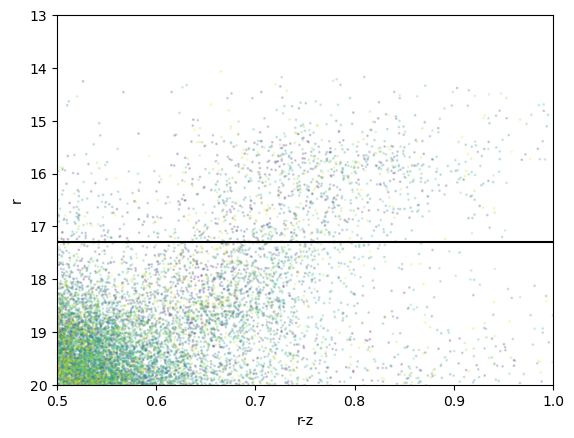

In [21]:
# This one just zooms in on the red clump portion of the CMD, I think

plt.figure()
plt.scatter(cmd.iloc[:,c1col]-cmd.iloc[:,c2col],cmd.iloc[:,mcol],c=cmd.iloc[:,1],s=1,alpha=0.2,rasterized=True) # plots the CMD color-coded by RA
#plt.scatter(giants.iloc[:,rcol]-giants.iloc[:,zcol],giants.iloc[:,rcol],c=giants.iloc[:,1],rasterized=True)
#plt.xlim(0.15,1.15)
plt.plot([colorcut,colorcut,cmax],[13.0,magcut,magcut],'k-') # plots the black line that shows the magnitude cut
plt.xlim(0.5,cmax)
plt.ylim(20,13)
#plt.gca().invert_yaxis()
if interactive==True:
    plt.ion()
    plt.show()
    cont = input("Type y to continue: ")
    if not (cont=="y" or cont=="Y"):
        sys.exit()
plt.xlabel('%s-%s' % (c1,c2))
plt.ylabel(mag)

pdf.savefig()

<>:33: SyntaxWarning: invalid escape sequence '\q'
<>:33: SyntaxWarning: invalid escape sequence '\q'
/tmp/slurmtmp.8723620/ipykernel_2180774/2953913643.py:33: SyntaxWarning: invalid escape sequence '\q'
  '\quad A_%s=%5.3f\pm%5.3f$' % (mag, magrc, np.sqrt(cov[2,2]), src, np.sqrt(cov[4,4]),


Text(0.5, 1.0, '$r_{\\rm rc}=15.934\\pm0.113,\\quad s_{\\rm rc}= 0.659\\pm0.114,\\quad A_r=0.859\\pm0.113$')

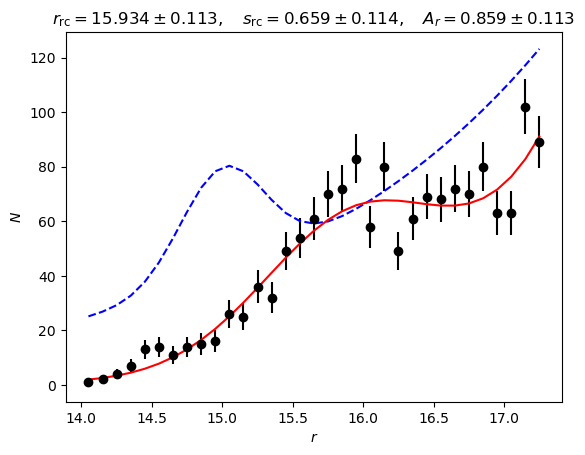

In [24]:

hist,be = np.histogram(giants.iloc[:,mcol],range=(magcut-4.0,magcut),bins=40,density=False) # bins the magnitudes of the giants, be is bin edges
bc = 0.5*(be[0:-1]+be[1:]) # calculates bin centers from the bin edges

mask = (hist>0) #select only the bins that aren't empty, apply that to the histogram and bin centers
hist=hist[mask]
bc=bc[mask]

plt.figure()
# plot the histogram as points
plt.errorbar(bc,hist,yerr=np.sqrt(hist),fmt='ko')

# initial guess for the curve fit
guess = [40.0,0.5,15.0,30.0,0.3]

# use curve fit to try fitting the histogram data to the rcmodel function
# first argument is the function, second is the bin centers, third is the histogram values
# p0 is your initial guess for the parameters
# sigma is the uncertainty, the square root of the histogram is a close enough approximation
par,cov = spopt.curve_fit(rcmodel,bc,hist,p0=guess,sigma=np.sqrt(hist))

# par an array of the best-fit parameters, this sets each parameter to its own variable
# cov is the array of errors from the fit, I think technically as a covariance matrix
A,B,magrc,Nrc,src = par

# plot your initial guess in blue and the best fit in red
plt.plot(bc,rcmodel(bc,*guess),'b--')
plt.plot(bc,rcmodel(bc,*par),'r-')

plt.xlabel(r'$%s$' % (mag))
plt.ylabel(r'$N$')

plt.title(r'$%s_{\rm rc}=%6.3f\pm%5.3f,\quad s_{\rm rc}=%6.3f\pm%5.3f,' \
          '\quad A_%s=%5.3f\pm%5.3f$' % (mag, magrc, np.sqrt(cov[2,2]), src, np.sqrt(cov[4,4]),
                                         mag, magrc-clumpmag0, np.sqrt(cov[2,2])))

# pdf.savefig()

Text(0, 0.5, '$N$')

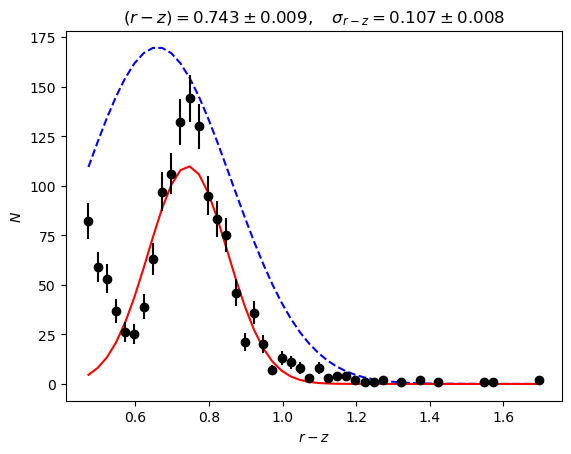

In [25]:
# From the giants, select only the red clump and repeat the fitting process from above
clumponly = giants[np.abs(giants.iloc[:,mcol]-magrc)<2*src]
hist2,be2 = np.histogram(clumponly.iloc[:,c1col]-clumponly.iloc[:,c2col],range=(colorcut,colorcut+1.5),bins=60,density=False)
bc2 = 0.5*(be2[0:-1]+be2[1:])

hist2mask = (hist2>0)
hist2 = hist2[hist2mask]
bc2=bc2[hist2mask]

guess2 = [par[3]+0.0,colorcut+0.2,0.2]

par2,cov2 = spopt.curve_fit(cgauss,bc2,hist2,p0=guess2,sigma=np.sqrt(hist2))

plt.figure()
plt.plot(bc2,cgauss(bc2,*guess2),'b--')
plt.plot(bc2,cgauss(bc2,*par2),'r-')

plt.errorbar(bc2,hist2,yerr=np.sqrt(hist2),fmt='ko')

plt.title(r'$(%s-%s)=%6.3f\pm%5.3f,\quad \sigma_{%s-%s}=%6.3f\pm%5.3f$' % (c1,c2,par2[1],np.sqrt(cov2[1,1]),c1,c2,par2[2],np.sqrt(cov2[2,2])))

plt.xlabel(r'$%s-%s$' % (c1,c2))
plt.ylabel(r'$N$')

# pdf.savefig()

In [28]:
fpfile = open(froot + '.fpext.txt','a')
# Print what you have so far + write it to a file
print('%s_rc = %6.3f +/- %5.3f,   src = %6.3f +/- %5.3f,   A_%s = %5.3f +/- %5.3f' %(mag,par[2],np.sqrt(cov[2,2]),par[4],np.sqrt(cov[4,4]),mag,par[2]-clump["clump-"+mag],np.sqrt(cov[2,2])))

magrc = par[2]
Amag = magrc-clump["clump-"+mag]

colorrc = np.nanmedian(clumponly.iloc[:,c1col]-clumponly.iloc[:,c2col])
colorrc = par2[1]
Ecolor = colorrc-(clump["clump-"+c1]-clump["clump-"+c2])
tot2sel = Amag/Ecolor
print('E(%s-%s) ='%(c1,c2),Ecolor,'  Tot/Sel =',tot2sel)

fpfile.write("#RA Dec l b A" + mag + " A"+c1 + " E("+c1+"-"+c2+")" + " A"+c1+"/E("+c1+"-"+c2+") distance RAmin RAmax Decmin Decmax\n")
fpfile.write("%9.5f %8.5f %g %g %g %g %g %g %g %g %g %g %g\n" % (a,d,l,b,Amag,Amag+Ecolor,Ecolor,tot2sel,clump["distance"],amin,amax,dmin,dmax))
RoA = tot2sel/Amag
fpfile.write("%9.5f %8.5f %g %g %g %g %g %g %g %g %g %g %g\n" % (0,0,0,0,np.sqrt(cov[2,2]),np.sqrt(cov[2,2]+cov2[2,2]),np.sqrt(cov2[2,2]),tot2sel*np.sqrt((cov[2,2])/Amag**2+cov2[2,2]/Ecolor**2),0,0,0,0,0))
fpfile.close()

r_rc = 15.934 +/- 0.113,   src =  0.659 +/- 0.114,   A_r = 0.859 +/- 0.113
E(r-z) = 0.32799532427470834   Tot/Sel = 2.617563617484719


Text(0, 0.5, '$r-z$')

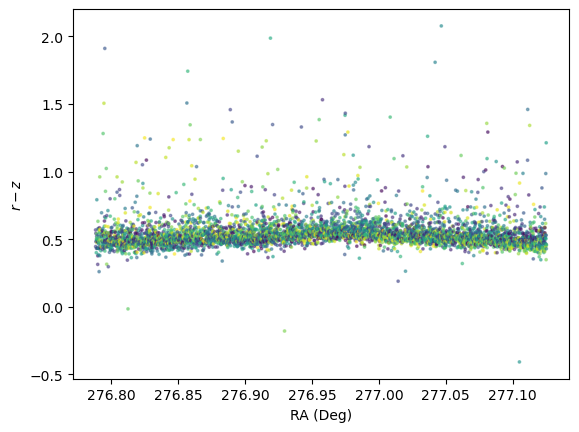

In [30]:
medcolor = colorrc-(clump["clump-"+c1]-clump["clump-"+c2]) # I'm not actually sure this gets used anywhere???

# select the main sequence turnoff + plot as a function of RA
# tbh I'm not really sure what this showing
#msto = cmd[(cmd.iloc[:,zcol]>=zcut+2.0) & (cmd.iloc[:,zcol]<zcut+2.0+0.5)]
msto = cmd[(cmd.iloc[:,mcol]>=magrc+3.5) & (cmd.iloc[:,mcol]<magrc+3.5+0.5)]

med_msto_color = np.nanmedian(msto.iloc[:,c1col]-msto.iloc[:,c2col])

plt.figure()
# plot MSTO color as function of RA, color code by Dec
plt.scatter(msto.iloc[:,1],msto.iloc[:,c1col]-msto.iloc[:,c2col],c=msto.iloc[:,2],s=3,alpha=0.5)
plt.xlabel('RA (Deg)')
plt.ylabel(r'$%s-%s$' % (c1,c2))
#plt.ylim([0.25,0.75])
#plt.ylim([0.5,1.5])
# pdf.savefig()

Text(0, 0.5, '$r$')

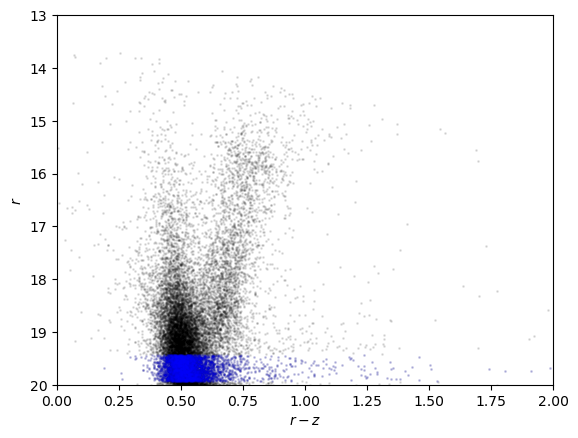

In [32]:
# Plot color-magnitude diagram with the MSTO highlighted
plt.figure()
plt.plot(cmd.iloc[:,c1col]-cmd.iloc[:,c2col],cmd.iloc[:,mcol],'ko',ms=1,alpha=0.1,rasterized=True)
plt.plot(msto.iloc[:,c1col]-msto.iloc[:,c2col],msto.iloc[:,mcol],'bo',ms=1,alpha=0.1,rasterized=True)
plt.xlim([0,2])
plt.ylim([20,13])
plt.xlabel(r'$%s-%s$' % (c1,c2))
plt.ylabel(r'$%s$' % (mag))
# pdf.savefig()

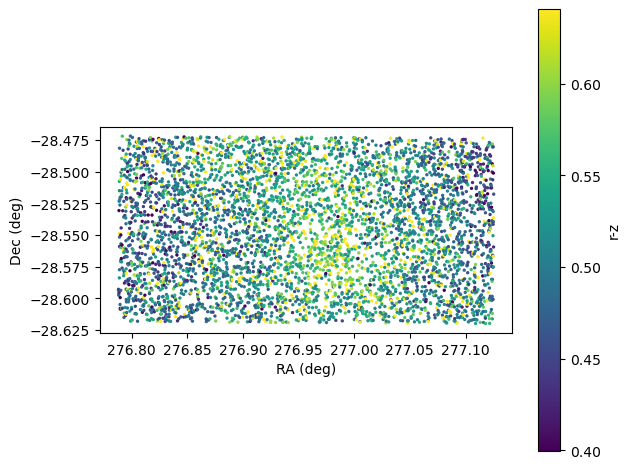

In [34]:
# Plots the color of the msto across the chip in RA and Dec. Color coded by the median color +/- the standard deviation of the color
plt.figure()
cmed = np.nanmedian(msto.iloc[:,c1col]-msto.iloc[:,c2col])
cstd = np.nanstd(msto.iloc[:,c1col]-msto.iloc[:,c2col])


plt.scatter(msto.iloc[:,1],msto.iloc[:,2],c=msto.iloc[:,c1col]-msto.iloc[:,c2col],s=2,vmin=cmed-cstd,vmax=cmed+cstd,rasterized=True)
cbar = plt.colorbar()
cbar.set_label('%s-%s' % (c1,c2))
plt.xlabel('RA (deg)')
plt.ylabel('Dec (deg)')
plt.gca().set_aspect(1.0/np.cos(d*np.pi/180.0))
plt.tight_layout()
# pdf.savefig()


#plt.figure(figsize=(16,8))
#fig, ax = plt.subplots(4,8)

In [35]:
print("RA (min med max):",amin,a,amax)
print("Dec (min med max):",dmin,d,dmax)
print("colorcut magcut:",colorcut,magcut)

# pdf.close()

RA (min med max): 276.788095 276.95672744421023 277.125526
Dec (min med max): -28.6199226 -28.545947733803064 -28.4719451
colorcut magcut: 0.46 17.3
